In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from skimage.feature import graycomatrix, graycoprops
from pathlib import Path

root = Path.cwd().resolve()

if root.name == "notebooks":
    root = root.parent

data = root / "datasets"
root = Path.cwd().resolve()

if root.name == "notebooks":
    root = root.parent

data = root / "datasets"

split_df = pd.read_csv(root / "shared" / "split.csv")

print(split_df["split"].value_counts())
display(split_df.head())

split
train    4361
test     1598
val       754
Name: count, dtype: int64


,filename,label,split
0,Training\glioma\Tr-gl_1.jpg,glioma,train
1,Training\glioma\Tr-gl_10.jpg,glioma,train
2,Training\glioma\Tr-gl_100.jpg,glioma,train
3,Training\glioma\Tr-gl_1000.jpg,glioma,train
4,Training\glioma\Tr-gl_1001.jpg,glioma,train


In [7]:
def extract_features(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise ValueError(f"Cannot read: {path}")

    img = cv2.resize(img, (224, 224))

    quantized = (img // 16).astype(np.uint8)

    glcm = graycomatrix(
        quantized,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=16,
        symmetric=True,
        normed=True
    )

    features = {}

    for name in ["contrast", "homogeneity", "energy", "correlation"]:
        features[name] = float(graycoprops(glcm, name).mean())

    features["mean_intensity"] = float(img.mean())
    features["std_intensity"] = float(img.std())

    return features

In [8]:
sample = split_df.iloc[0]

features = extract_features(data / sample["filename"])

print("Class:", sample["label"])
print("\nExtracted features:")

for name, value in features.items():
    print(f"{name}: {value:.4f}")

Class: glioma

Extracted features:
contrast: 0.8810
homogeneity: 0.8456
energy: 0.4630
correlation: 0.9030
mean_intensity: 34.4748
std_intensity: 36.4389


In [11]:
from tqdm.auto import tqdm

records = []

for _, row in tqdm(split_df.iterrows(), total=len(split_df)):
    features = extract_features(data / row["filename"])

    features["filename"] = row["filename"]
    features["label"] = row["label"]
    features["split"] = row["split"]

    records.append(features)

features_df = pd.DataFrame(records)

(root / "shared").mkdir(exist_ok=True)

features_df.to_csv(
    root / "shared" / "features.csv",
    index=False
)

print("Feature extraction completed!")
print("Total images processed:", len(features_df))
print("Features CSV saved successfully!")

display(features_df.head())

C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 6713/6713 [00:38<00:00, 175.10it/s]


Feature extraction completed!
Total images processed: 6713
Features CSV saved successfully!


,contrast,homogeneity,energy,correlation,mean_intensity,std_intensity,filename,label,split
0,0.881021,0.845564,0.463038,0.902982,34.474849,36.438912,Training\glioma\Tr-gl_1.jpg,glioma,train
1,1.162435,0.795786,0.379715,0.921130,48.602519,44.257674,Training\glioma\Tr-gl_10.jpg,glioma,train
2,0.877489,0.852605,0.496744,0.943236,43.697166,45.906352,Training\glioma\Tr-gl_100.jpg,glioma,train
3,1.035927,0.823879,0.405514,0.911337,41.279695,39.707398,Training\glioma\Tr-gl_1000.jpg,glioma,train
4,0.657567,0.904667,0.651155,0.940618,27.339365,39.637415,Training\glioma\Tr-gl_1001.jpg,glioma,train


In [12]:
print("Dataset shape:", features_df.shape)

print("\nMissing values:")
print(features_df.isnull().sum())

print("\nImages per split:")
print(features_df["split"].value_counts())

Dataset shape: (6713, 9)

Missing values:
contrast          0
homogeneity       0
energy            0
correlation       0
mean_intensity    0
std_intensity     0
filename          0
label             0
split             0
dtype: int64

Images per split:
split
train    4361
test     1598
val       754
Name: count, dtype: int64


In [13]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [14]:
cols = [
    "contrast",
    "homogeneity",
    "energy",
    "correlation",
    "mean_intensity",
    "std_intensity"
]

train = features_df[features_df["split"] == "train"]
val = features_df[features_df["split"] == "val"]

X_train = train[cols]
y_train = train["label"]

X_val = val[cols]
y_val = val["label"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (4361, 6)
Validation: (754, 6)


In [15]:
svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
)

svm.fit(X_train, y_train)

print("SVM training completed!")

C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!


In [16]:
val_pred = svm.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, val_pred))

print("\nClassification Report:")
print(classification_report(y_val, val_pred))

Validation Accuracy: 0.773209549071618

Classification Report:
              precision    recall  f1-score   support

      glioma       0.77      0.70      0.73       219
  meningioma       0.65      0.72      0.68       181
     notumor       0.94      0.80      0.86       159
   pituitary       0.80      0.88      0.83       195

    accuracy                           0.77       754
   macro avg       0.79      0.78      0.78       754
weighted avg       0.78      0.77      0.77       754



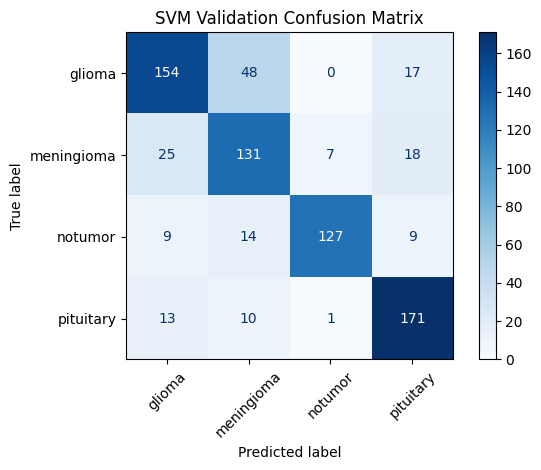

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("SVM Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

params = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1]
}

grid = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=42
        )
    ),
    params,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1-score:", grid.best_score_)

C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters: {'svc__C': 100, 'svc__gamma': 1}
Best CV F1-score: 0.8158893321836503


Tuned Validation Accuracy: 0.8156498673740054

Classification Report:
              precision    recall  f1-score   support

      glioma       0.77      0.75      0.76       219
  meningioma       0.73      0.75      0.74       181
     notumor       0.90      0.88      0.89       159
   pituitary       0.88      0.90      0.89       195

    accuracy                           0.82       754
   macro avg       0.82      0.82      0.82       754
weighted avg       0.82      0.82      0.82       754



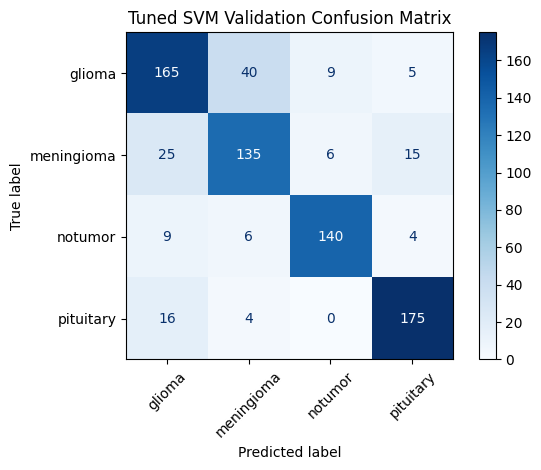

In [19]:
best_svm = grid.best_estimator_

tuned_pred = best_svm.predict(X_val)

print("Tuned Validation Accuracy:",
      accuracy_score(y_val, tuned_pred))

print("\nClassification Report:")
print(classification_report(y_val, tuned_pred))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    tuned_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Tuned SVM Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [20]:
import joblib

(root / "models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_svm,
    root / "models" / "svm.pkl"
)

print("Tuned SVM saved successfully!")

Tuned SVM saved successfully!


In [21]:
loaded_svm = joblib.load(root / "models" / "svm.pkl")

pred = loaded_svm.predict(X_val)

print("Loaded model accuracy:", accuracy_score(y_val, pred))

Loaded model accuracy: 0.8156498673740054


Test Data:

In [22]:
from sklearn.metrics import accuracy_score, classification_report

test = features_df[features_df["split"] == "test"]

X_test = test[cols]
y_test = test["label"]

test_pred = loaded_svm.predict(X_test)
test_probs = loaded_svm.predict_proba(X_test)

print("Test Accuracy:", accuracy_score(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

Test Accuracy: 0.7196495619524406

Classification Report:
              precision    recall  f1-score   support

      glioma       0.68      0.57      0.62       399
  meningioma       0.64      0.55      0.59       399
     notumor       0.68      0.87      0.76       400
   pituitary       0.87      0.90      0.88       400

    accuracy                           0.72      1598
   macro avg       0.72      0.72      0.71      1598
weighted avg       0.72      0.72      0.71      1598



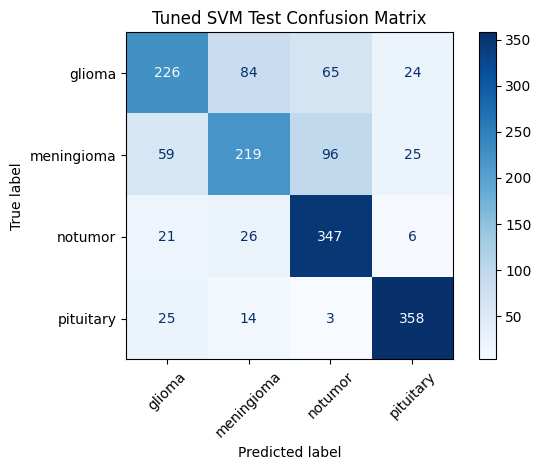

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Tuned SVM Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [24]:
results = test[["filename", "label", "split"]].copy()

results["predicted_label"] = test_pred

for i, cls in enumerate(loaded_svm.classes_):
    results[f"prob_{cls}"] = test_probs[:, i]

results.to_csv(
    root / "shared" / "preds_svm.csv",
    index=False
)

print("SVM predictions saved!")
display(results.head())

SVM predictions saved!


,filename,label,split,predicted_label,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary
5115,Testing\glioma\Te-gl_1.jpg,glioma,test,notumor,0.049958,0.140175,0.739038,0.070829
5116,Testing\glioma\Te-gl_10.jpg,glioma,test,glioma,0.838604,0.028326,0.041145,0.091924
5117,Testing\glioma\Te-gl_100.jpg,glioma,test,glioma,0.972189,0.023985,0.002887,0.000939
5118,Testing\glioma\Te-gl_101.jpg,glioma,test,notumor,0.101314,0.298441,0.512012,0.088233
5119,Testing\glioma\Te-gl_102.jpg,glioma,test,pituitary,0.348036,0.004741,0.060828,0.586396


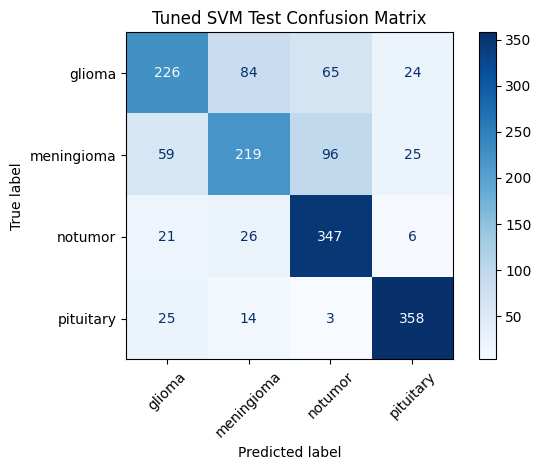

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Tuned SVM Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    root / "outputs" / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

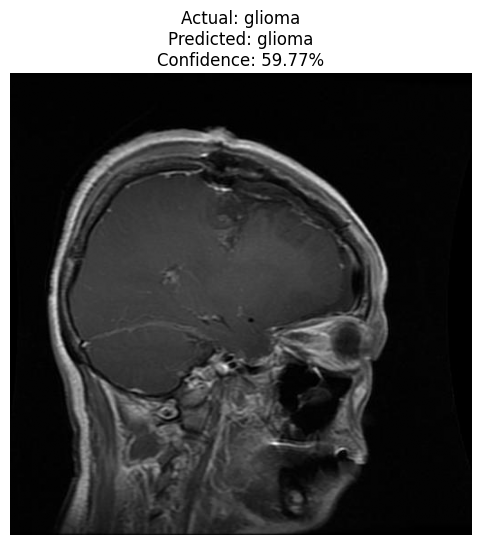

In [5]:
import joblib
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

root = Path.cwd().resolve()

if root.name == "notebooks":
    root = root.parent

data = root / "datasets"
model = joblib.load(root / "models" / "svm.pkl")
split_df = pd.read_csv(root / "shared" / "split.csv")
test = split_df[split_df["split"] == "test"]

sample = test.sample(1).iloc[0]

img_path = data / Path(sample["filename"].replace("\\", "/"))
import numpy as np
from skimage.feature import graycomatrix, graycoprops

def extract_features(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise ValueError(f"Cannot read: {path}")

    img = cv2.resize(img, (224, 224))
    quantized = (img // 16).astype(np.uint8)

    glcm = graycomatrix(
        quantized,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=16,
        symmetric=True,
        normed=True
    )

    features = {}

    for name in ["contrast", "homogeneity", "energy", "correlation"]:
        features[name] = float(graycoprops(glcm, name).mean())

    features["mean_intensity"] = float(img.mean())
    features["std_intensity"] = float(img.std())

    return features
features = extract_features(img_path)

cols = [
    "contrast", "homogeneity", "energy",
    "correlation", "mean_intensity", "std_intensity"
]

X = pd.DataFrame([features])[cols]

prediction = model.predict(X)[0]
confidence = model.predict_proba(X)[0].max() * 100

img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.title(
    f"Actual: {sample['label']}\n"
    f"Predicted: {prediction}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()